# HIV NSPPK Bayesian optimization

Tune NSPPK encoder parameters with `NSPPKClassifier.tune()`, then refit the selected encoder and fixed random forest on the full training split. The final cell reports full-data held-out performance with a metric chart, confusion matrices, ROC curve, and precision–recall curve.

In [1]:
from pathlib import Path
import pickle
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(path for path in REPO_CANDIDATES if (path / 'src').exists())
SRC_DIR = REPO_ROOT / 'src'
NOTEBOOK_DIR = REPO_ROOT / 'notebooks'
for path in (SRC_DIR, NOTEBOOK_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from nsppk import NSPPK, NSPPKClassifier
from hiv_tuning_utils import (
    balanced_training_sample, plot_heldout_report, plot_tuning_progress,
    split_train_test, tuning_result_frame,
)

# User-editable experiment parameters.
RANDOM_STATE = 2026
BUDGET_PER_CLASS = 2_000
TEST_SIZE = 0.25
CV_FOLDS = 3
N_TRIALS = 20
N_INITIAL_POINTS = 10
NBITS = 14
PARALLEL = True
SEARCH_SPACE = {
    'radius': (1, 3),
    'distance': (2, 6),
    'connector': (0, 2),
    'use_simplex_features': [False, True],
    'simplex_feature_order': [2, 3],
}
RF_SETTINGS = {
    'n_estimators': 300,
    'criterion': 'gini',
    'max_features': 'sqrt',
    'max_depth': None,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'bootstrap': True,
    'class_weight': 'balanced_subsample',
    'n_jobs': -1,
    'random_state': RANDOM_STATE,
}
HIV_PICKLE = REPO_ROOT / 'data' / 'HIV_networkx_graphs.pkl'
print('BO search space:', SEARCH_SPACE)
print(f'BO budget: {BUDGET_PER_CLASS:,} per class; hash width: {NBITS}')
print('Fixed random forest:', RF_SETTINGS)

BO search space: {'radius': (1, 3), 'distance': (2, 6), 'connector': (0, 2), 'use_simplex_features': [False, True], 'simplex_feature_order': [2, 3]}
BO budget: 2,000 per class; hash width: 14
Fixed random forest: {'n_estimators': 300, 'criterion': 'gini', 'max_features': 'sqrt', 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1, 'bootstrap': True, 'class_weight': 'balanced_subsample', 'n_jobs': -1, 'random_state': 2026}


## Prepare the full train/test split and BO cohort

The test split is reserved before tuning. The user-defined balanced sample is drawn only from the training partition; its effective size is capped by the available active examples.

In [2]:
with HIV_PICKLE.open('rb') as handle:
    hiv_data = pickle.load(handle)
all_graphs = hiv_data['graphs']
y_all = np.asarray(hiv_data['labels'], dtype=np.int8)

if not np.array_equal(np.unique(y_all), np.array([0, 1])):
    raise ValueError('Expected the binary HIV activity labels 0 and 1.')
full_train_idx, full_test_idx = split_train_test(
    y_all, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
tuning_idx, effective_per_class = balanced_training_sample(
    y_all, full_train_idx, BUDGET_PER_CLASS, random_state=RANDOM_STATE
)

tuning_graphs = [all_graphs[i] for i in tuning_idx]
y_tuning = y_all[tuning_idx]
full_train_graphs = [all_graphs[i] for i in full_train_idx]
y_full_train = y_all[full_train_idx]
full_test_graphs = [all_graphs[i] for i in full_test_idx]
y_full_test = y_all[full_test_idx]

print(f'Full dataset: {len(all_graphs):,}; classes={np.bincount(y_all).tolist()}')
print(f'Train/test: {len(full_train_idx):,}/{len(full_test_idx):,}')
print(f'Train classes: {np.bincount(y_full_train).tolist()}')
print(f'Test classes: {np.bincount(y_full_test).tolist()}')
print(f'Effective tuning sample: {len(tuning_idx):,} ({effective_per_class:,} per class)')

Full dataset: 41,120; classes=[39677, 1443]
Train/test: 30,840/10,280
Train classes: [29758, 1082]
Test classes: [9919, 361]
Effective tuning sample: 2,164 (1,082 per class)


## Tune the NSPPK encoder

The classifier configuration remains fixed across all trials. `tune()` performs the Latin-hypercube and Gaussian-process search, then refits the winning wrapper on the tuning cohort.

In [3]:
tuning_model = NSPPKClassifier(
    estimator='rf',
    estimator_params=RF_SETTINGS,
    nbits=NBITS,
    dense=False,
    parallel=PARALLEL,
)
tuning_started = time.perf_counter()
tune_result = tuning_model.tune(
    tuning_graphs,
    y_tuning,
    search_space=SEARCH_SPACE,
    scoring='average_precision',
    cv=CV_FOLDS,
    n_samples=N_TRIALS,
    n_initial_points=N_INITIAL_POINTS,
    random_state=RANDOM_STATE,
    verbose=True,
)
tuning_seconds = time.perf_counter() - tuning_started
best_params = dict(tune_result.best_params)
print(f'BO completed in {tuning_seconds / 60:.1f} minutes')
print('Best NSPPK settings:', best_params)
print(f'Best mean CV average precision: {tune_result.best_score:.4f}')

Iteration No: 1 started. Evaluating function at random point.


Trial 01/20: average_precision=0.84033; params={'radius': np.int64(2), 'distance': np.int64(5), 'connector': np.int64(2), 'use_simplex_features': np.True_, 'simplex_feature_order': np.int64(2)}
Iteration No: 1 ended. Evaluation done at random point.
Time taken: 19.9239
Function value obtained: -0.8403
Current minimum: -0.8403
Iteration No: 2 started. Evaluating function at random point.


Trial 02/20: average_precision=0.77940; params={'radius': np.int64(3), 'distance': np.int64(4), 'connector': np.int64(1), 'use_simplex_features': np.False_, 'simplex_feature_order': np.int64(3)}
Iteration No: 2 ended. Evaluation done at random point.
Time taken: 5.8107
Function value obtained: -0.7794
Current minimum: -0.8403
Iteration No: 3 started. Evaluating function at random point.


Trial 03/20: average_precision=0.85387; params={'radius': np.int64(1), 'distance': np.int64(3), 'connector': np.int64(1), 'use_simplex_features': np.True_, 'simplex_feature_order': np.int64(3)}
Iteration No: 3 ended. Evaluation done at random point.
Time taken: 5.2850
Function value obtained: -0.8539
Current minimum: -0.8539
Iteration No: 4 started. Evaluating function at random point.


Trial 04/20: average_precision=0.85162; params={'radius': np.int64(2), 'distance': np.int64(4), 'connector': np.int64(0), 'use_simplex_features': np.True_, 'simplex_feature_order': np.int64(3)}
Iteration No: 4 ended. Evaluation done at random point.
Time taken: 10.9233
Function value obtained: -0.8516
Current minimum: -0.8539
Iteration No: 5 started. Evaluating function at random point.


Trial 05/20: average_precision=0.81143; params={'radius': np.int64(2), 'distance': np.int64(2), 'connector': np.int64(2), 'use_simplex_features': np.False_, 'simplex_feature_order': np.int64(2)}
Iteration No: 5 ended. Evaluation done at random point.
Time taken: 3.7340
Function value obtained: -0.8114
Current minimum: -0.8539
Iteration No: 6 started. Evaluating function at random point.


... (12 outputs left out)

Trial 18/20: average_precision=0.84941; params={'radius': np.int64(1), 'distance': np.int64(2), 'connector': np.int64(0), 'use_simplex_features': np.False_, 'simplex_feature_order': np.int64(3)}
Iteration No: 18 ended. Search finished for the next optimal point.
Time taken: 2.6440
Function value obtained: -0.8494
Current minimum: -0.8592
Iteration No: 19 started. Searching for the next optimal point.


Trial 19/20: average_precision=0.85573; params={'radius': np.int64(2), 'distance': np.int64(2), 'connector': np.int64(0), 'use_simplex_features': np.True_, 'simplex_feature_order': np.int64(2)}
Iteration No: 19 ended. Search finished for the next optimal point.
Time taken: 6.2357
Function value obtained: -0.8557
Current minimum: -0.8592
Iteration No: 20 started. Searching for the next optimal point.


Trial 20/20: average_precision=0.85541; params={'radius': np.int64(1), 'distance': np.int64(2), 'connector': np.int64(2), 'use_simplex_features': np.True_, 'simplex_feature_order': np.int64(3)}
Iteration No: 20 ended. Search finished for the next optimal point.
Time taken: 6.4111
Function value obtained: -0.8554
Current minimum: -0.8592


BO completed in 3.8 minutes
Best NSPPK settings: {'radius': np.int64(1), 'distance': np.int64(2), 'connector': np.int64(0), 'use_simplex_features': np.True_, 'simplex_feature_order': np.int64(2)}
Best mean CV average precision: 0.8592


## Review BO history

,radius,distance,connector,use_simplex_features,simplex_feature_order,trial,score,score_std,fold_scores
0,1,2,0,True,2,11,0.8592,0.0135,"[0.873141673203561, 0.8581304621003044, 0.8462..."
1,1,2,0,True,3,12,0.8592,0.0135,"[0.873141673203561, 0.8581304621003044, 0.8462..."
2,2,2,0,True,2,19,0.8557,0.0139,"[0.8706558465626373, 0.8534484686196191, 0.843..."
3,1,2,2,True,3,20,0.8554,0.0151,"[0.8718723793913531, 0.8519952966168844, 0.842..."
4,1,3,1,True,3,3,0.8539,0.0137,"[0.8688554569540687, 0.8508467978425831, 0.841..."
5,2,4,0,True,3,4,0.8516,0.0118,"[0.8641022606928351, 0.8500145419832148, 0.840..."
6,3,2,0,True,3,14,0.8513,0.0124,"[0.863941418103233, 0.8507927223422654, 0.8392..."
7,1,2,0,False,3,18,0.8494,0.0157,"[0.8663799560044823, 0.8465102668370124, 0.835..."
8,1,6,0,True,3,13,0.8474,0.0152,"[0.8632097089563964, 0.8460967361057746, 0.832..."
9,3,3,0,True,2,7,0.8463,0.0127,"[0.8598434763441566, 0.8443680111731333, 0.834..."


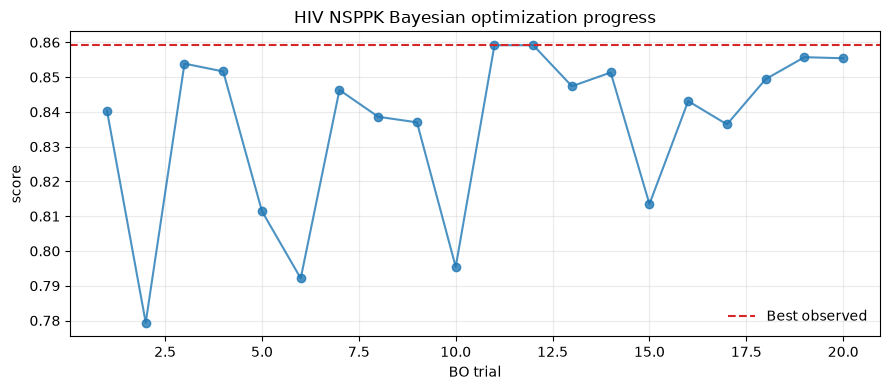

In [4]:
bo_results = tuning_result_frame(tune_result)
display(bo_results.head(10).round(4))
progress_figure = plot_tuning_progress(
    bo_results, score_column='score', title='HIV NSPPK Bayesian optimization progress'
)
plt.show()

## Full-data train/test experiment

Expose `NSPPK` directly here: build the best graph features for the complete training split, transform the untouched test split, and fit the same fixed random forest.

,train_examples,test_examples,train_active,test_active,test_active_prevalence,budget_per_class_requested,budget_per_class_effective,radius,distance,connector,...,nbits,accuracy,balanced_accuracy,macro_f1,roc_auc,average_precision,precision_at_0.5,recall_at_0.5,feature_seconds,classifier_fit_seconds
0,30840,10280,1082,361,0.0351,2000,1082,1,2,0,...,14,0.9725,0.6841,0.7371,0.8599,0.5008,0.7031,0.374,36.7113,4.6346


,pred_0,pred_1
true_0,9862,57
true_1,226,135


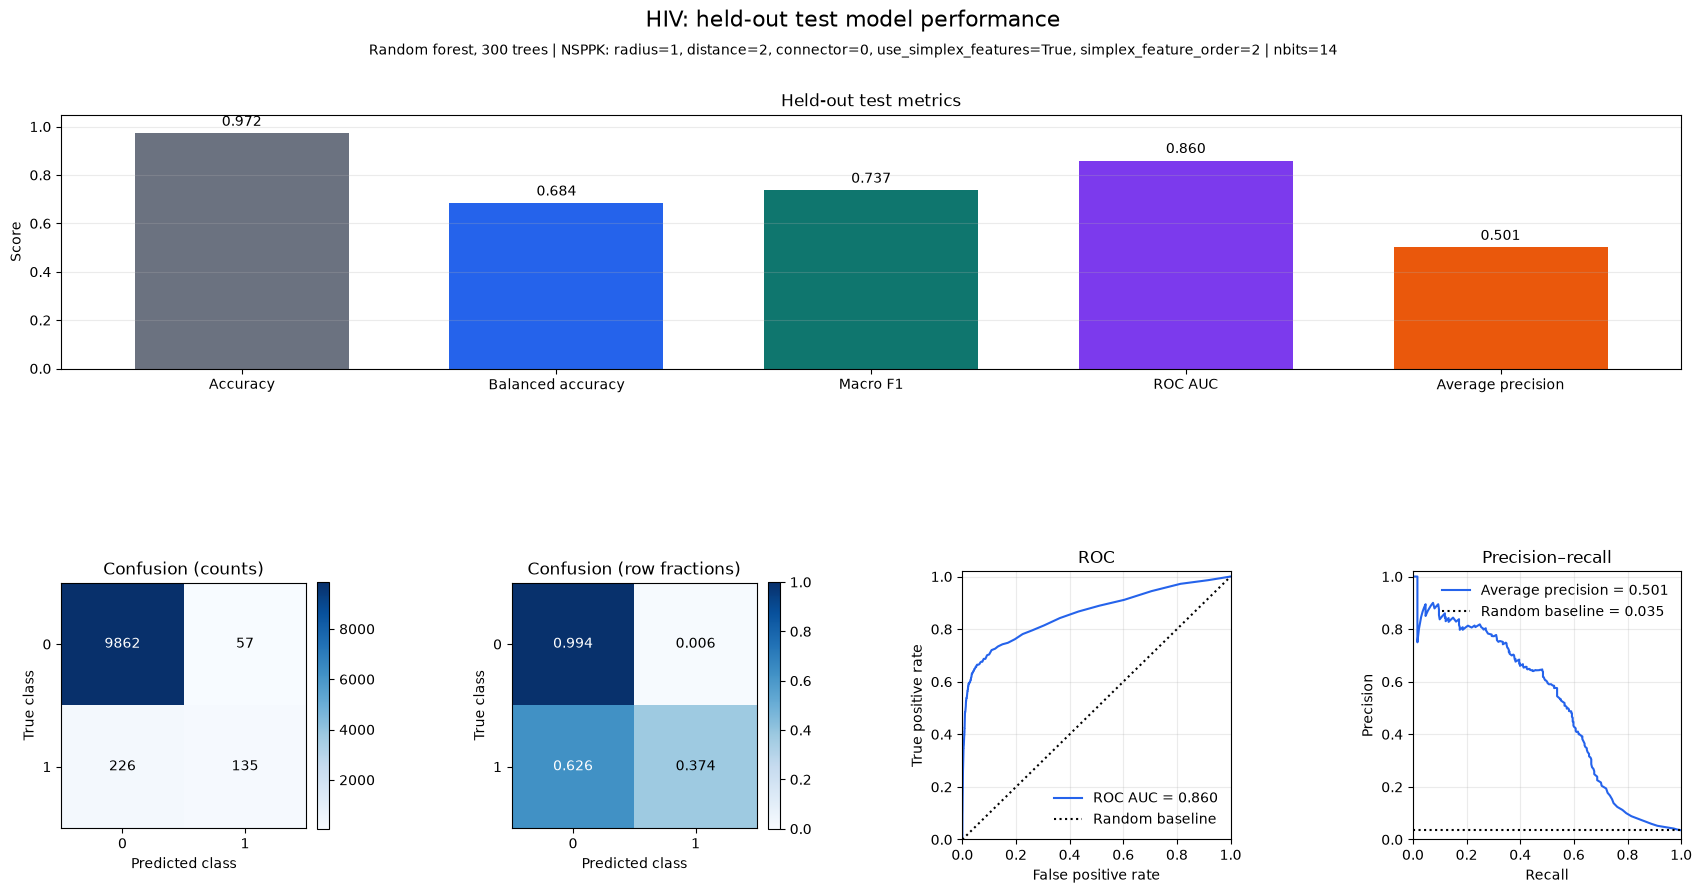

Saved test report figure: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/NSPPK/data/hiv_nsppk_bo_full_test_report.png


In [5]:
# Direct NSPPK use with the best settings returned by .tune().
final_encoder = NSPPK(
    **best_params,
    nbits=NBITS,
    dense=False,
    parallel=PARALLEL,
)
feature_started = time.perf_counter()
X_full_train = final_encoder.fit_transform(full_train_graphs)
X_full_test = final_encoder.transform(full_test_graphs)
feature_seconds = time.perf_counter() - feature_started

final_classifier = RandomForestClassifier(**RF_SETTINGS)
fit_started = time.perf_counter()
final_classifier.fit(X_full_train, y_full_train)
classifier_fit_seconds = time.perf_counter() - fit_started
test_probabilities = final_classifier.predict_proba(X_full_test)[:, 1]
test_predictions = final_classifier.predict(X_full_test)

test_metrics, confusion, report_figure = plot_heldout_report(
    y_full_test,
    test_probabilities,
    test_predictions,
    best_params=best_params,
    nbits=NBITS,
    classifier_label='Random forest, 300 trees',
)
full_test_summary = pd.DataFrame([{
    'train_examples': len(y_full_train),
    'test_examples': len(y_full_test),
    'train_active': int(y_full_train.sum()),
    'test_active': int(y_full_test.sum()),
    'test_active_prevalence': float(y_full_test.mean()),
    'budget_per_class_requested': BUDGET_PER_CLASS,
    'budget_per_class_effective': effective_per_class,
    **best_params,
    'nbits': NBITS,
    **test_metrics,
    'feature_seconds': feature_seconds,
    'classifier_fit_seconds': classifier_fit_seconds,
}])
display(full_test_summary.round(4))
display(pd.DataFrame(confusion, index=['true_0', 'true_1'], columns=['pred_0', 'pred_1']))
REPORT_FIGURE = REPO_ROOT / 'data' / 'hiv_nsppk_bo_full_test_report.png'
report_figure.savefig(REPORT_FIGURE, dpi=180, bbox_inches='tight')
plt.show()
print('Saved test report figure:', REPORT_FIGURE)

## Save results

In [6]:
RESULTS_PATH = REPO_ROOT / 'data' / 'hiv_nsppk_bo_results.csv'
bo_results.to_csv(RESULTS_PATH, index=False)
SUMMARY_PATH = REPO_ROOT / 'data' / 'hiv_nsppk_bo_full_test_metrics.csv'
full_test_summary.to_csv(SUMMARY_PATH, index=False)
print('Saved BO trials:', RESULTS_PATH)
print('Saved full test metrics:', SUMMARY_PATH)

Saved BO trials: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/NSPPK/data/hiv_nsppk_bo_results.csv
Saved full test metrics: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/NSPPK/data/hiv_nsppk_bo_full_test_metrics.csv
